In [ ]:
# Titanic Survival Prediction
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")
print("Titanic Survival Prediction Project")

Libraries imported successfully!
Titanic Survival Prediction Project


In [ ]:
# Step 2: Load the Titanic dataset

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# Step 3: Explore the dataset

print("Dataset Information:")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSurvival Counts:")
print(df["Survived"].value_counts())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
Number of rows: 891
Number of columns: 12

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Survival Counts:
Survived
0    549
1    342
Name: count, dtype: int64

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


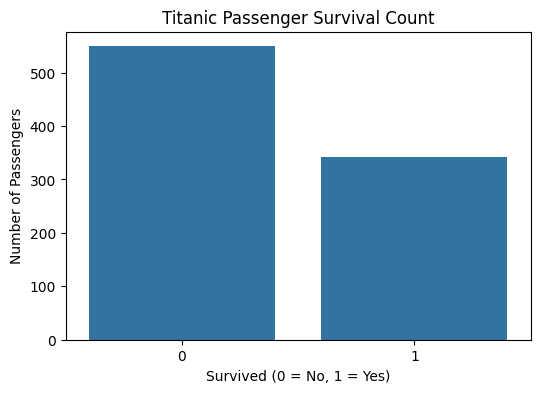

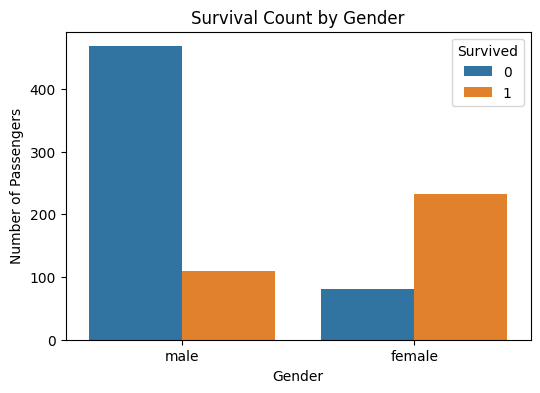

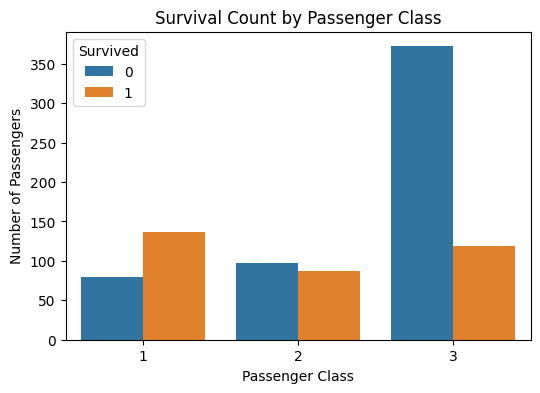

In [ ]:
# Step 4: Visualize survival patterns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Survived")
plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Sex", hue="Survived")
plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Pclass", hue="Survived")
plt.title("Survival Count by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.show()

In [ ]:
# Step 5: Prepare data and train the model

# Select useful features
features = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked"
]

X = df[features].copy()
y = df["Survived"]

# Convert categorical columns into numerical columns
X = pd.get_dummies(
    X,
    columns=["Sex", "Embarked"],
    drop_first=True,
    dtype=int
)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Handle missing values and scale features
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

# Predict on unseen test records
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("Model trained successfully!")
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model trained successfully!
Model Accuracy: 80.45%

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



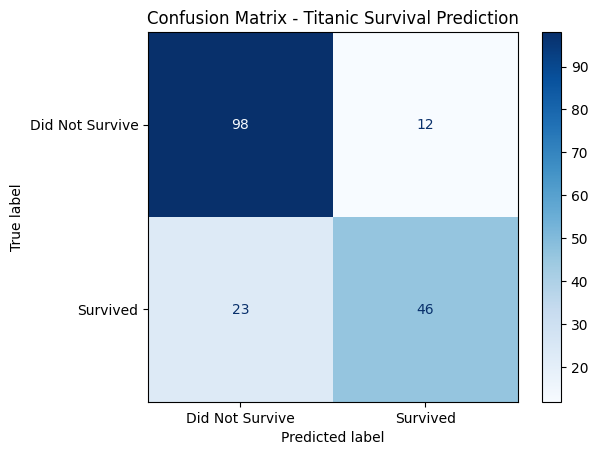

Confusion Matrix:
[[98 12]
 [23 46]]


In [ ]:

# Step 6: Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Titanic Survival Prediction")
plt.show()

print("Confusion Matrix:")
print(cm)


In [ ]:
# Step 7: Sample Passenger Predictions

sample_passengers = pd.DataFrame({
    "Pclass": [1, 3, 2],
    "Sex": ["female", "male", "female"],
    "Age": [25, 30, 20],
    "SibSp": [0, 0, 1],
    "Parch": [0, 0, 0],
    "Fare": [80, 8, 26],
    "Embarked": ["S", "S", "C"]
})

# Apply the same encoding used during training
sample_encoded = pd.get_dummies(
    sample_passengers,
    columns=["Sex", "Embarked"],
    drop_first=True,
    dtype=int
)

# Ensure the input columns match the training columns
sample_encoded = sample_encoded.reindex(
    columns=X_train.columns,
    fill_value=0
)

predictions = model.predict(sample_encoded)

for i, prediction in enumerate(predictions):
    result = "Survived" if prediction == 1 else "Did Not Survive"
    print(f"Passenger {i+1}: {result}")

Passenger 1: Survived
Passenger 2: Did Not Survive
Passenger 3: Survived


In [ ]:
# Step 8: Save model and prediction results

import joblib

joblib.dump(model, "titanic_model.pkl")

results = pd.DataFrame({
    "Actual Survival": y_test.values,
    "Predicted Survival": y_pred
})

results.to_csv("titanic_predictions.csv", index=False)

print("Model saved as titanic_model.pkl")
print("Predictions saved as titanic_predictions.csv")

Model saved as titanic_model.pkl
Predictions saved as titanic_predictions.csv


In [9]:
from google.colab import files

files.download("titanic_model.pkl")
files.download("titanic_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>